# PCA vs t-SNE vs UMAP on cancer gene expression

**Module 03.1 · my implementation**, Seid Adem

**Question:** when 20,000-dimensional gene-expression profiles are squeezed onto a 2-D map, **what does each method
keep, and what does it distort?** Instead of judging the pictures by eye, I score every map with three numbers and
test how stable the maps are.

> **New to this?** The background you need:
> * **Gene expression** = how active each of ~20,000 genes is in a sample, measured by RNA sequencing. Different
>   tissues switch on different genes, so a tumour's profile reflects the organ it came from.
>   ([Gene-expression lessons](../../../05_group_projects/gene_expression/LESSONS.md))
> * **TCGA** (The Cancer Genome Atlas) is a public collection of ~11,000 tumour profiles across 33 cancer types.
> * **Dimensionality reduction** draws a 2-D map in which similar samples sit close together.
>   ([Lesson 6](../LESSONS.md#lesson-6--a-tour-of-the-algorithm-families))

## The design: cancer types with built-in "answers"

I chose 12 cancer types so that the expected structure is known in advance:

| Pair (same organ) | Codes | Expectation |
|-------------------|-------|-------------|
| Lung adenocarcinoma / lung squamous cell carcinoma | LUAD / LUSC | same organ, different cell of origin: close but separable |
| Kidney clear cell / papillary carcinoma | KIRC / KIRP | same organ: close |
| Lower-grade glioma / glioblastoma (brain) | LGG / GBM | same tissue, different grade: close, partly overlapping |
| Colon / rectum adenocarcinoma | COAD / READ | molecularly very similar; TCGA analysed them together as *COADREAD* |
| Breast, prostate, thyroid, liver | BRCA, PRAD, THCA, LIHC | unrelated organs: well separated |

In the figures, **each pair shares a hue** (light and dark), so related types are easy to spot.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyreadr
import seaborn as sns
import umap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

from dsls.expression import (
    balanced_subsample,
    centroid_distance_correlation,
    knn_label_agreement,
    tcga_sample_type,
    top_variable_genes,
)

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
# umap-learn warns that a fixed random_state disables parallelism; that is intended here (reproducibility)
warnings.filterwarnings("ignore", message="n_jobs value", category=UserWarning)

## 1 · Load, select primary tumours, balance the classes

> **In plain language.** TCGA sample IDs encode the sample type in their last two digits: `01` is a primary tumour,
> `11` is normal tissue next to the tumour, `06` is a metastasis. Mixing them would blur the picture, so only
> primary tumours are kept. Taking **60 tumours per type** stops breast cancer (over 1,000 samples) from dominating.
> The `tcga_sample_type` and `balanced_subsample` helpers are unit-tested in
> [`src/dsls/expression.py`](../../../src/dsls/expression.py).

The values are log2-transformed, normalised RNA-seq expression (UCSC Xena "HiSeqV2" style), so 0 means "not expressed"
and each +1 doubles the expression.

In [2]:
DATA = Path("../../../data/raw/gene_expression")
SEED = 0

# 12 cancer types: 8 that come in biologically related pairs, plus 4 unrelated ones
TYPES = {
    "lung adenocarcinoma": "LUAD", "lung squamous cell carcinoma": "LUSC",
    "kidney clear cell carcinoma": "KIRC", "kidney papillary cell carcinoma": "KIRP",
    "brain lower grade glioma": "LGG", "glioblastoma multiforme": "GBM",
    "colon adenocarcinoma": "COAD", "rectum adenocarcinoma": "READ",
    "breast invasive carcinoma": "BRCA", "prostate adenocarcinoma": "PRAD",
    "thyroid carcinoma": "THCA", "liver hepatocellular carcinoma": "LIHC",
}  # fmt: skip
ORDER = list(TYPES.values())
PALETTE = dict(zip(ORDER, sns.color_palette("Paired", 12), strict=True))  # related pairs share a hue

expr_all = pyreadr.read_r(DATA / "pan_cancer_dataset.RDS")[None].set_index("gene").T  # samples × genes
labels_all = pd.read_csv(DATA / "labels.tsv", sep="\t").set_index("sample")["_primary_disease"]
assert expr_all.index.is_unique and expr_all.columns.is_unique
assert set(expr_all.index) <= set(labels_all.index), "every expression sample has a label"

primary = [s for s in expr_all.index if tcga_sample_type(s) == "01"]  # primary tumours only
labels = labels_all.loc[primary]
labels = labels[labels.isin(TYPES)].map(TYPES)
subset = balanced_subsample(labels, n_per_class=60, seed=SEED)
expr = expr_all.loc[subset.index]
y = subset.to_numpy()

print(f"full matrix: {expr_all.shape[0]:,} samples × {expr_all.shape[1]:,} genes")
print(f"primary tumours of the 12 types: {len(labels):,}; balanced subset: {len(subset)} (60 per type)")

full matrix: 10,459 samples × 20,530 genes
primary tumours of the 12 types: 5,360; balanced subset: 720 (60 per type)


## 2 · Preprocess without looking at the labels

> **In plain language.** Most genes barely change between samples and only add noise. We keep the **2,000 genes that
> vary most** across the 720 samples, standardise each one (mean 0, SD 1) so that no gene dominates because of its
> scale, and compress them to **50 principal components**. This choice uses **no labels**: the cancer types are only
> used later, to *judge* the maps. Using labels to choose the genes would make the maps look better than they are.

In [3]:
genes = top_variable_genes(expr, 2000)
Z = StandardScaler().fit_transform(expr[genes])
start = time.perf_counter()
pca = PCA(n_components=50, random_state=SEED)
P = pca.fit_transform(Z)
pca_seconds = time.perf_counter() - start

print(f"{(expr.var() == 0).sum()} genes are constant in this subset and can carry no information")
print("10 most variable genes:", ", ".join(genes[:10]))
print(
    f"variance explained: PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}, "
    f"first 50 PCs {pca.explained_variance_ratio_.sum():.1%}"
)

263 genes are constant in this subset and can carry no information
10 most variable genes: CEACAM5, GFAP, CEACAM6, SFTPB, AGR2, XIST, FGG, FABP1, FGA, FGB
variance explained: PC1 26.3%, PC2 14.3%, first 50 PCs 83.0%


**A confounder hiding among the top genes.** *XIST* is switched on only in cells with two X chromosomes (female), and
*RPS4Y1* sits on the Y chromosome (male). They are among the most variable genes because **patient sex** changes
expression, independently of cancer type. All breast tumours here are from women and all prostate tumours from men,
so sex and cancer type are partly entangled. Which principal component does sex load on?

In [4]:
sex_corr = pd.DataFrame(
    {g: [np.corrcoef(P[:, i], expr[g])[0, 1] for i in range(10)] for g in ["XIST", "RPS4Y1"]},
    index=[f"PC{i + 1}" for i in range(10)],
).T.round(2)
sex_corr

,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10
XIST,-0.01,-0.08,0.11,0.02,-0.23,-0.11,0.40,-0.17,-0.08,0.20
RPS4Y1,-0.11,0.07,-0.14,-0.05,0.25,0.07,-0.44,0.08,0.20,-0.21


Sex has its own axis (**PC7**, |r| ≈ 0.4 with both genes), *behind* six components dominated by tissue of origin.
The maps below are therefore driven by tissue, which is what we want. In a study comparing cancer *within* one organ,
though, sex could easily be the strongest signal, and it would need to be checked first.

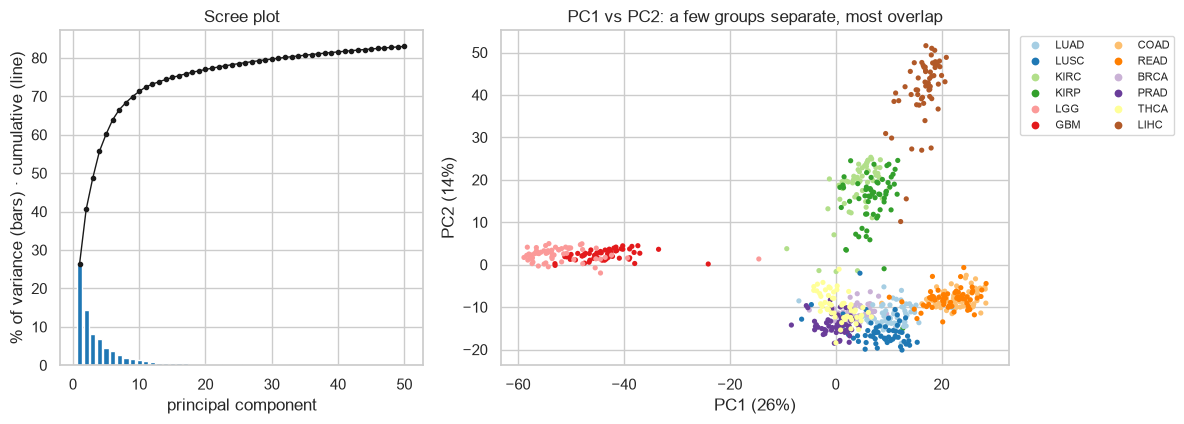

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.4), gridspec_kw={"width_ratios": [1, 1.4]})
ax1.bar(range(1, 51), pca.explained_variance_ratio_ * 100, color="tab:blue")
ax1.plot(range(1, 51), np.cumsum(pca.explained_variance_ratio_) * 100, color="k", marker=".", lw=1)
ax1.set(xlabel="principal component", ylabel="% of variance (bars) · cumulative (line)", title="Scree plot")
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=y, hue_order=ORDER, palette=PALETTE, s=14, linewidth=0, ax=ax2)
ax2.set(
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
    title="PC1 vs PC2: a few groups separate, most overlap",
)
ax2.legend(ncol=2, fontsize=8, markerscale=1.5, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIGURES / "05_pca_overview.png", dpi=150, bbox_inches="tight")
plt.show()

> **In plain language.** The first two components hold about 40 % of the variation in the 2,000 genes. Brain tumours
> and a few other types stand apart, but most types pile on top of each other. Twelve groups simply don't fit into two
> *straight* directions. That is the motivation for non-linear methods.

## 3 · Three maps of the same data

> **In plain language.**
> * **PCA** rotates the data and shows the two directions of greatest spread. It is a fixed, mathematical projection,
>   so distances on the map are meaningful but much is squashed.
> * **t-SNE** and **UMAP** start from each sample's *nearest neighbours* in the full data and try to place
>   neighbours close together on the map. They untangle clusters well, but they **don't** promise that distances
>   *between* clusters, or cluster sizes, mean anything.
>
> Both are run on the 50 PCs (standard practice: it removes noise and speeds them up).

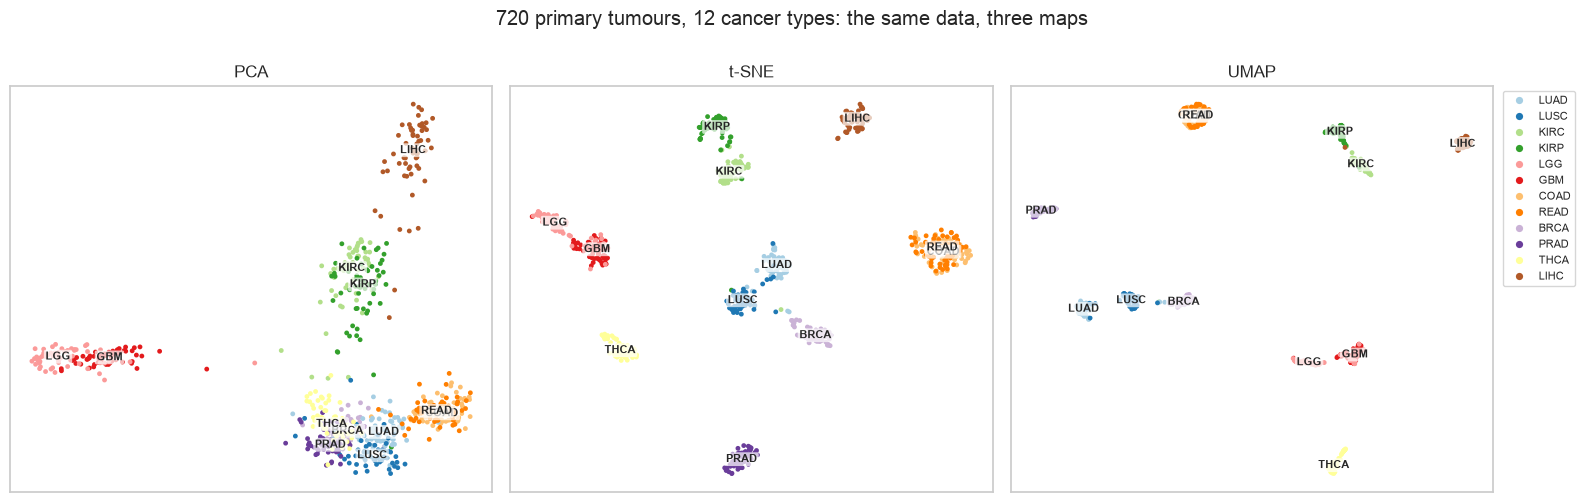

In [6]:
maps = {"PCA": P[:, :2]}
timings = {"PCA": pca_seconds}  # PCA was fitted in section 2
for name, make in {
    "t-SNE": lambda: TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED),
    "UMAP": lambda: umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED),
}.items():
    start = time.perf_counter()
    maps[name] = make().fit_transform(P)
    timings[name] = time.perf_counter() - start

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, E) in zip(axes, maps.items(), strict=True):
    sns.scatterplot(
        x=E[:, 0],
        y=E[:, 1],
        hue=y,
        hue_order=ORDER,
        palette=PALETTE,
        s=12,
        linewidth=0,
        ax=ax,
        legend=name == "UMAP",
    )
    for code_ in ORDER:  # label each type at its median position
        cx, cy = np.median(E[y == code_], axis=0)
        ax.text(
            cx,
            cy,
            code_,
            fontsize=8,
            weight="bold",
            ha="center",
            va="center",
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7),
        )
    ax.set(title=name, xticks=[], yticks=[])
axes[-1].legend(ncol=1, fontsize=8, markerscale=1.5, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("720 primary tumours, 12 cancer types: the same data, three maps", y=1.0)
fig.tight_layout()
fig.savefig(FIGURES / "06_three_maps.png", dpi=150, bbox_inches="tight")
plt.show()

By eye, t-SNE and UMAP look far "better". To go beyond "looks better", the next section measures what each map keeps.

## 4 · Scoring the maps

Three questions, three scores:

| Score | Question | How |
|-------|----------|-----|
| **Neighbour label agreement** | Do tumours of the same type sit together on the map? | accuracy of a 10-nearest-neighbour classifier, cross-validated, *on the 2-D map* |
| **Trustworthiness** | Are neighbours on the map really neighbours in the data? (1 = no false neighbours) | `sklearn.manifold.trustworthiness` against the 50-PC space |
| **Global layout (ρ)** | Are types that are similar in the data also close on the map? | Spearman correlation of type-to-type centroid distances, data vs map |

The first and third scores are implemented and unit-tested in `dsls.expression`. For reference, the same neighbour
score in the full 50-PC space is the **ceiling** a map could reach.

In [7]:
ceiling = knn_label_agreement(P, y)
scores = pd.DataFrame(
    {
        name: {
            "neighbour label agreement": knn_label_agreement(E, y),
            "trustworthiness": trustworthiness(P, E, n_neighbors=10),
            "global layout ρ": centroid_distance_correlation(P, E, y),
            "seconds": timings[name],
        }
        for name, E in maps.items()
    }
).T
print(f"neighbour label agreement in the 50-PC space (ceiling): {ceiling:.3f}")
scores.round(3)

neighbour label agreement in the 50-PC space (ceiling): 0.890


,neighbour label agreement,trustworthiness,global layout ρ,seconds
PCA,0.692,0.930,0.953,0.052
t-SNE,0.881,0.993,0.548,2.175
UMAP,0.890,0.989,0.421,5.691


**What the numbers say**

* **Local structure:** t-SNE and UMAP keep almost all neighbourhood information (label agreement about 0.88, the same
  as the 50-PC ceiling of 0.89; trustworthiness about 0.99). The 2-D PCA map loses a lot (0.69).
* **Global structure:** PCA keeps the arrangement of cancer types (ρ = 0.95). t-SNE (0.55) and UMAP (0.42) keep it
  only partly.

**So each method answers a different question.** PCA: *how do the groups relate overall?* t-SNE/UMAP: *which samples
belong together?*

Why isn't the ceiling 1.0? Some types are genuinely hard to tell apart even with all 50 components:

In [8]:
pred = cross_val_predict(
    KNeighborsClassifier(10), P, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED)
)
confusion = pd.crosstab(pd.Series(y, name="true"), pd.Series(pred, name="predicted"))
recall = pd.Series(np.diag(confusion.loc[ORDER, ORDER]) / 60, index=ORDER).round(2)
mix_ups = [
    (t, p, int(confusion.loc[t, p])) for t in ORDER for p in ORDER if t != p and confusion.loc[t, p] >= 3
]
print("per-type recall:", recall.to_dict())
print("most frequent mix-ups (true → predicted, count):", sorted(mix_ups, key=lambda m: -m[2]))

per-type recall: {'LUAD': 0.98, 'LUSC': 0.92, 'KIRC': 0.97, 'KIRP': 0.95, 'LGG': 0.82, 'GBM': 0.98, 'COAD': 0.73, 'READ': 0.35, 'BRCA': 1.0, 'PRAD': 1.0, 'THCA': 1.0, 'LIHC': 0.98}
most frequent mix-ups (true → predicted, count): [('READ', 'COAD', 39), ('COAD', 'READ', 16), ('LGG', 'GBM', 10), ('LUSC', 'LUAD', 4)]


> **In plain language.** **Rectal tumours are recognised as rectal only 35 % of the time.** Most are called colon.
> This is not a failure of the method; it reflects biology. Colon and rectal adenocarcinomas arise from the same
> kind of gut lining and have very similar molecular profiles, which is why TCGA analysed them as one disease.
> The other confusions are the brain pair (LGG → GBM) and, rarely, the lung pair (LUSC → LUAD): exactly the
> related pairs designed into the dataset. On the maps above, the COAD and READ labels land on the same spot.

## 5 · How stable is each map?

> **In plain language.** t-SNE and UMAP involve randomness. If a conclusion changes when you change the random seed,
> it was never a property of the data. Below, UMAP is run with 10 seeds and t-SNE with 5 seeds under two
> initialisations: random, and starting from the PCA map.

In [9]:
stability = []
for s in range(10):
    E = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=s).fit_transform(P)
    stability.append(
        {
            "method": "UMAP",
            "seed": s,
            "global layout ρ": centroid_distance_correlation(P, E, y),
            "neighbour label agreement": knn_label_agreement(E, y),
        }
    )
for init in ["pca", "random"]:
    for s in range(5):
        E = TSNE(perplexity=30, init=init, random_state=s).fit_transform(P)
        stability.append(
            {
                "method": f"t-SNE ({init} init)",
                "seed": s,
                "global layout ρ": centroid_distance_correlation(P, E, y),
                "neighbour label agreement": knn_label_agreement(E, y),
            }
        )
stability = pd.DataFrame(stability)
stability.groupby("method")[["global layout ρ", "neighbour label agreement"]].agg(
    ["min", "median", "max"]
).round(2)

global layout ρ              neighbour label agreement  \
                                min median   max                       min   
method                                                                       
UMAP                           0.21   0.43  0.56                      0.88   
t-SNE (pca init)               0.55   0.55  0.55                      0.88   
t-SNE (random init)            0.35   0.44  0.48                      0.88   

                                  
                    median   max  
method                            
UMAP                  0.88  0.89  
t-SNE (pca init)      0.88  0.88  
t-SNE (random init)   0.88  0.88

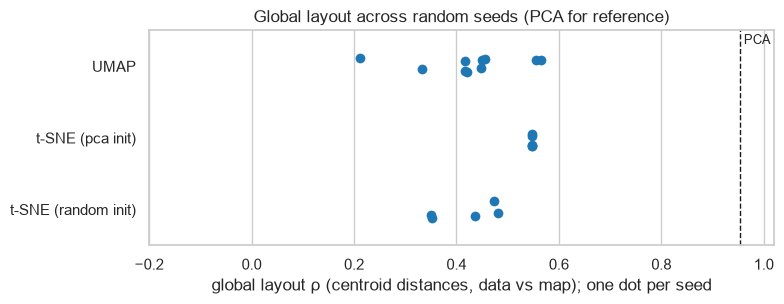

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.stripplot(data=stability, y="method", x="global layout ρ", size=7, jitter=0.15, color="tab:blue", ax=ax)
ax.axvline(scores.loc["PCA", "global layout ρ"], color="k", ls="--", lw=1)
ax.text(scores.loc["PCA", "global layout ρ"], -0.45, " PCA", va="top", fontsize=9)
ax.set(
    xlim=(-0.2, 1.02), ylabel="", xlabel="global layout ρ (centroid distances, data vs map); one dot per seed"
)
ax.set_title("Global layout across random seeds (PCA for reference)")
fig.tight_layout()
fig.savefig(FIGURES / "07_seed_stability.png", dpi=150)
plt.show()

* **Neighbourhoods are robust:** label agreement barely moves between seeds for any method.
* **UMAP's global layout depends on the seed** (ρ from 0.21 to 0.56 over 10 seeds). Which clusters end up next to each
  other on a UMAP plot is partly luck.
* **t-SNE with PCA initialisation is fully reproducible** and keeps more of the global layout than random
  initialisation. Starting from PCA "anchors" the big picture, which is why it is the scikit-learn default.

## 6 · The tuning knobs: perplexity and n_neighbors

> **In plain language.** Both methods have one main setting for "how many neighbours count as local": **perplexity**
> for t-SNE and **n_neighbors** for UMAP. Small values focus on fine detail, large values on the bigger picture.

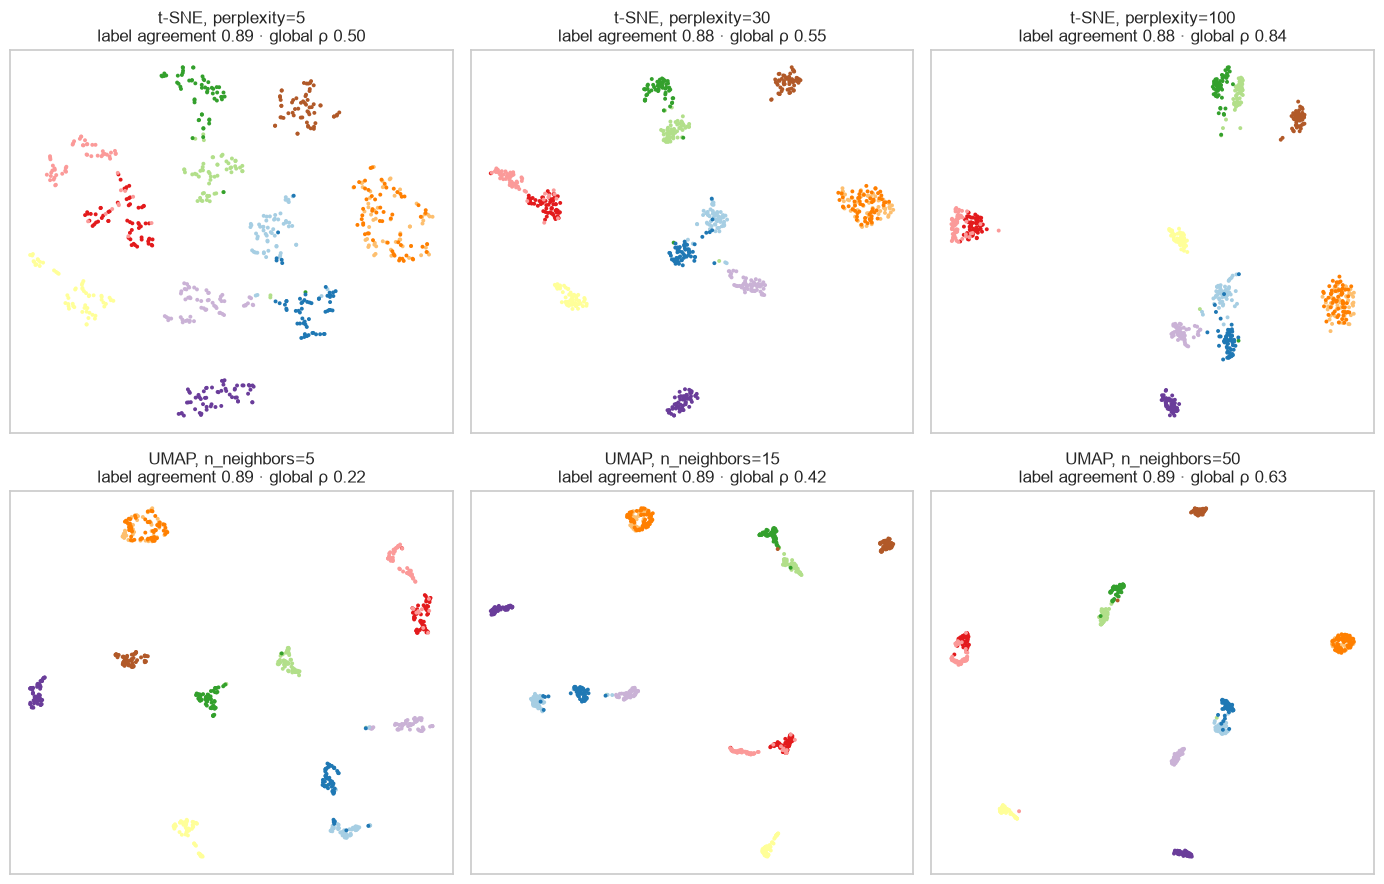

,method,perplexity,label agreement,global ρ,n_neighbors
0,t-SNE,5.0,0.890,0.497,NaN
1,t-SNE,30.0,0.881,0.548,NaN
2,t-SNE,100.0,0.881,0.836,NaN
3,UMAP,NaN,0.888,0.220,5.0
4,UMAP,NaN,0.890,0.421,15.0
5,UMAP,NaN,0.889,0.631,50.0


In [11]:
sweep = [
    ("t-SNE", "perplexity", v, lambda v: TSNE(perplexity=v, init="pca", random_state=SEED))
    for v in (5, 30, 100)
]
sweep += [
    ("UMAP", "n_neighbors", v, lambda v: umap.UMAP(n_neighbors=v, random_state=SEED)) for v in (5, 15, 50)
]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
rows = []
for ax, (method, knob, value, make) in zip(axes.ravel(), sweep, strict=True):
    E = make(value).fit_transform(P)
    agree, rho = knn_label_agreement(E, y), centroid_distance_correlation(P, E, y)
    rows.append({"method": method, knob: value, "label agreement": agree, "global ρ": rho})
    sns.scatterplot(
        x=E[:, 0], y=E[:, 1], hue=y, hue_order=ORDER, palette=PALETTE, s=8, linewidth=0, ax=ax, legend=False
    )
    ax.set(
        title=f"{method}, {knob}={value}\nlabel agreement {agree:.2f} · global ρ {rho:.2f}",
        xticks=[],
        yticks=[],
    )
fig.tight_layout()
fig.savefig(FIGURES / "08_hyperparameters.png", dpi=150)
plt.show()
pd.DataFrame(rows).round(3)

Neighbour label agreement hardly changes (about 0.88 throughout), so for "which samples belong together" the setting
matters little here. **Larger perplexity keeps more of the global layout** (ρ rises from about 0.5 at perplexity 5 to
about 0.8 at 100). Look at the panels as well as the numbers:

* At **perplexity 5**, single cancer types (e.g. LUSC, LGG) break into several small islands. **Those islands are not
  subtypes**; they are what a too-small neighbourhood does. Never report "new subgroups" from one t-SNE setting.
* At **perplexity 100**, the related pairs (kidney, brain, lung) move next to each other, which matches the higher ρ.
 UMAP's ρ also rises with `n_neighbors` (0.22 → 0.63), but section 5 showed that the seed alone
moves it by about ±0.2, so treat that trend as suggestive rather than proven.

## Conclusions

1. **Choose the method by the question.** PCA for the overall relationships between groups (ρ = 0.95, deterministic,
   interpretable axes); t-SNE or UMAP to see which samples cluster together (neighbour agreement 0.88–0.89 vs 0.69).
2. **Don't read distances between clusters on t-SNE/UMAP plots.** UMAP's global layout varied from ρ = 0.21 to 0.56
   just by changing the random seed.
3. **Fix the seed and initialise t-SNE from PCA** for reproducible maps. Report the settings.
4. **The data's real structure is organ-level.** Colon and rectum are essentially indistinguishable; the brain pair
   overlaps partly; the lung and kidney pairs separate well.
5. **Look for confounders among the top genes.** Sex genes are in the top 15, so in a single-organ study they would
   need to be handled explicitly.

The [clustering notebook](03_tcga_clustering_kmeans_vs_hierarchical.ipynb) asks the follow-up question: can an
algorithm find these groups *without* being given the labels?

---
*Data: TCGA pan-cancer RNA-seq (via UCSC Xena, as distributed with the course's gene-expression project); fetched with
`scripts/fetch_course_materials.sh --data` into git-ignored `data/raw/gene_expression/`. TCGA data are open access
under the NIH GDC data-use policy. Runs in about 1–2 minutes on a laptop.*